IMPORTING THE BASIC LIBRARIES FOR MATH AND LHS

In [58]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

# Default figure font styling
plt.rcParams.update({
    'font.family': 'Times New Roman',
    'font.size': 11,
    'font.weight': 'bold',
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',
    'axes.titlesize': 11,
    'axes.labelsize': 11,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 11,
    'figure.titleweight': 'bold',
    'axes.prop_cycle': cycler(color=['black'] * 4, linestyle=['-', '--', ':', '-.']),
    'axes.grid': True,
    'grid.color': '0.7',
    'grid.linewidth': 0.8,
    'axes.edgecolor': 'black',
    'axes.linewidth': 1.0,
    'xtick.top': True,
    'ytick.right': True,
    'legend.frameon': False,
    'lines.linewidth': 1.5,
    'figure.facecolor': 'white',
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'axes.facecolor': 'white',
})

def figure_legend(ax, ncol=3):
    """Place a frameless legend above the axes."""
    return ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02),
                     ncol=ncol, frameon=False)

rng = np.random.default_rng(2026)


PHYSICS-BASED MODEL: TWO EXPERIMENTAL INPUTS, TWO CALIBRATION PARAMETERS AND A TIME-DEPENDENT OUTPUT

In [59]:
import numpy as np

def physics_model(x, theta, time, gravity=9.81):
    """Distance curve under linear drag; x=(mass, release height), theta=(drag, gravity factor)."""
    x, theta, time = np.asarray(x, float), np.asarray(theta, float), np.asarray(time, float)
    if x.shape[-1] != 2 or theta.shape[-1] != 2 or np.any(x[..., 0] <= 0) or np.any(theta <= 0) or np.any(time < 0):
        raise ValueError('x and theta must have two components; mass and theta must be positive and time non-negative.')
    tau = x[..., 0] / theta[..., 0]
    return x[..., 1] + gravity * theta[..., 1] * tau * (time + tau * np.expm1(-time / tau))

LHS DESIGN: EACH SIMULATOR RUN RETURNS A FUNCTIONAL OUTPUT ON THE SAME TIME GRID

In [60]:
from scipy.stats import qmc
from sklearn.model_selection import train_test_split

n_sim = 100
# GP coordinates are x1, x2, theta1, theta2, and time.
lower_bounds = np.array([0.8, 0.0, 0.2, 0.8, 0.0])
upper_bounds = np.array([1.2, 0.5, 2.0, 1.2, 1.2])
design_unit = qmc.LatinHypercube(d=4, seed=2026).random(n_sim)
design = qmc.scale(design_unit, lower_bounds[:4], upper_bounds[:4])
time_sim = np.linspace(0, 1.2, 21)
y_curves = np.array([physics_model(row[:2], row[2:], time_sim) for row in design])
# Split by whole runs to prevent points from the same curve leaking into the test set.
train_runs, test_runs = train_test_split(np.arange(n_sim), test_size=0.2, random_state=2026)
print('Design:', design.shape, 'Functional simulator output:', y_curves.shape)

Design: (100, 4) Functional simulator output: (100, 21)


SVD BASIS FOR FUNCTIONAL SIMULATOR OUTPUT

In [61]:
# Build the functional-output basis using training runs only.
# Each row of y_curves is one simulator run; columns are time coordinates.
svd_training_curves = y_curves[train_runs]
svd_test_curves = y_curves[test_runs]
svd_mean_curve = svd_training_curves.mean(axis=0)
svd_scale = np.std(svd_training_curves - svd_mean_curve)
if not np.isfinite(svd_scale) or svd_scale <= 0:
    raise ValueError("Training curves need nonzero finite variation for SVD")

svd_training_standardized = (svd_training_curves - svd_mean_curve) / svd_scale
U, singular_values, Vt = np.linalg.svd(svd_training_standardized, full_matrices=False)
explained = np.cumsum(singular_values**2) / np.sum(singular_values**2)
variance_target = 0.9999
n_basis = int(np.searchsorted(explained, variance_target) + 1)
svd_basis = Vt[:n_basis]  # Each row is a basis curve over time_sim.
svd_weights_train = svd_training_standardized @ svd_basis.T

# Reconstruction diagnostics use no test data to select the basis.
train_reconstruction = svd_mean_curve + svd_scale * (svd_weights_train @ svd_basis)
test_standardized = (svd_test_curves - svd_mean_curve) / svd_scale
test_reconstruction = svd_mean_curve + svd_scale * ((test_standardized @ svd_basis.T) @ svd_basis)
print(f"SVD components: {n_basis}; training variation retained: {explained[n_basis - 1]:.4%}")
print(f"Training reconstruction RMSE: {np.sqrt(np.mean((svd_training_curves - train_reconstruction)**2)):.6f} m")
print(f"Held-out reconstruction RMSE: {np.sqrt(np.mean((svd_test_curves - test_reconstruction)**2)):.6f} m")

def svd_basis_at_times(times):
    """Evaluate the training mean and basis at times within the simulator grid."""
    times = np.asarray(times, dtype=float)
    if times.ndim != 1 or not np.all(np.isfinite(times)):
        raise ValueError('Times must be a finite one-dimensional array')
    if np.any((times < time_sim[0]) | (times > time_sim[-1])):
        raise ValueError('Times must lie within the simulator time grid')
    mean = np.interp(times, time_sim, svd_mean_curve)
    basis = np.column_stack([np.interp(times, time_sim, row) for row in svd_basis])
    return mean, svd_scale * basis

mean_grid, basis_grid = svd_basis_at_times(time_sim)
assert np.allclose(mean_grid, svd_mean_curve)
assert np.allclose(basis_grid, svd_scale * svd_basis.T)


SVD components: 3; training variation retained: 99.9990%
Training reconstruction RMSE: 0.001359 m
Held-out reconstruction RMSE: 0.001257 m


CREATING ALL MEASURED DATA

In [62]:
time_obs = np.linspace(0.15, 1.15, 10)
x_conditions = np.array([[0.85, 0.10], [1.15, 0.40]])
theta_true = np.array([0.8, 1.05])
x_obs = np.repeat(x_conditions, len(time_obs), axis=0)
t_obs = np.tile(time_obs, len(x_conditions))
y_sim_true = physics_model(x_obs, theta_true, t_obs)
delta_true = 0.15 * t_obs**2

Generating measurement noise

In [63]:
rng = np.random.default_rng(2026)
sigma_obs = 0.05  # Measurement noise standard deviation in metres
noise = rng.normal(0.0, sigma_obs, size=len(t_obs))

In [64]:
y_obs = y_sim_true + delta_true + noise

In [65]:
i = rng.integers(len(t_obs))
print('Condition (mass, initial distance):', x_obs[i])
print(f'Time: {t_obs[i]:.2f} s; observed distance: {y_obs[i]:.3f} m')

Condition (mass, initial distance): [1.15 0.4 ]
Time: 0.93 s; observed distance: 4.172 m


Normalizing and standardizing the inputs and outputs. 

In [66]:
# Expand each functional run into (x1, x2, theta1, theta2, time) coordinates.
X_physical = np.column_stack((np.repeat(design, len(time_sim), axis=0), np.tile(time_sim, n_sim)))
X_gp = qmc.scale(X_physical, lower_bounds, upper_bounds, reverse=True)
y_gp = y_curves.ravel()
run_index = np.repeat(np.arange(n_sim), len(time_sim))
print('GP coordinates:', X_gp.shape, 'outputs:', y_gp.shape)

GP coordinates: (2100, 5) outputs: (2100,)


Splitting data into training and testing data. Note its a forward emulator for regression so we will need holdout x 

In [67]:
# Retain 100 training coordinates for the original dense GP workflow.
# All test coordinates belong to different simulator runs.
rng_design = np.random.default_rng(2026)
eligible = np.flatnonzero(np.isin(run_index, train_runs))
selected = rng_design.choice(eligible, size=100, replace=False)
test_indices = np.flatnonzero(np.isin(run_index, test_runs))
X_train, X_test = X_gp[selected], X_gp[test_indices]
y_train_raw, y_test_raw = y_gp[selected], y_gp[test_indices]
y_mean, y_std = y_train_raw.mean(), y_train_raw.std()
y_train, y_test = (y_train_raw - y_mean) / y_std, (y_test_raw - y_mean) / y_std
print('Training points:', X_train.shape, 'held-out points:', X_test.shape)

Training points: (100, 5) held-out points: (420, 5)


Defining the GP emulator and its hyperparameters, and kernel

In [68]:
# Initial GP hyperparameters
lengthscale = np.ones(5)  # x1, x2, theta1, theta2, time
signal_variance = 1.0

# Small diagonal term for numerical stability - nugget
alpha = 1e-8

# RBF covariance function
def rbf_kernel(X1, X2, lengthscale, signal_variance):
    # Scale each input column by its length scale
    X1_scaled = X1 / lengthscale
    X2_scaled = X2 / lengthscale

    # Squared distance between every pair of input points
    squared_distance = np.sum(
        (X1_scaled[:, None, :] - X2_scaled[None, :, :])**2,
        axis=2
    )

    return signal_variance * np.exp(-0.5 * squared_distance)

CONSTRUCTING THE GP COVARIANCE MATRIX

In [69]:
# Covariance between all pairs of training points
K = rbf_kernel(
    X_train,
    X_train,
    lengthscale,
    signal_variance
)

# Add numerical jitter to the diagonal - adding nugget to the diagonals. 
K = K + alpha * np.eye(len(X_train))

print("Covariance matrix shape:", K.shape)

Covariance matrix shape: (100, 100)


Defining the GP log likelihood

In [70]:
def gp_log_likelihood(X, y, lengthscale, signal_variance, alpha=1e-8):
    # Build the covariance matrix and add jitter
    K = rbf_kernel(X, X, lengthscale, signal_variance)
    K = K + alpha * np.eye(len(X))

    # Cholesky decomposition: K = L @ L.T
    L = np.linalg.cholesky(K)

    # Solve K⁻¹y without explicitly calculating the inverse
    v = np.linalg.solve(L, y)
    K_inv_y = np.linalg.solve(L.T, v)

    log_likelihood = (
        -0.5 * y @ K_inv_y
        - np.sum(np.log(np.diag(L)))
        - 0.5 * len(y) * np.log(2 * np.pi)
    )

    return log_likelihood


# Evaluate it at our initial hyperparameter values
log_likelihood = gp_log_likelihood(
    X_train,
    y_train,
    lengthscale,
    signal_variance,
    alpha
)

print("Initial GP log likelihood:", log_likelihood)

Initial GP log likelihood: 94.05261874317155


defining the prior distributions

In [71]:
from scipy.stats import lognorm

def log_prior(lengthscale, signal_variance):
    if np.any(lengthscale <= 0) or signal_variance <= 0:
        return -np.inf

    # Log-normal priors, each with median 1.0
    log_p_lengthscale = np.sum(
        lognorm.logpdf(lengthscale, s=1.0, scale=1.0)
    )

    log_p_variance = lognorm.logpdf(
        signal_variance, s=1.0, scale=1.0
    )

    return log_p_lengthscale + log_p_variance


print("Initial log prior:", log_prior(lengthscale, signal_variance))

Initial log prior: -5.513631199228035


Combining prior and likelihood to generate the posterior

In [72]:
def log_posterior(X, y, lengthscale, signal_variance):
    # Check whether the hyperparameters are plausible under the priors
    lp = log_prior(lengthscale, signal_variance)

    if not np.isfinite(lp):
        return -np.inf

    # Evaluate how well they explain the simulator data
    ll = gp_log_likelihood(
        X,
        y,
        lengthscale,
        signal_variance
    )

    return lp + ll


print(
    "Initial log posterior:",
    log_posterior(X_train, y_train, lengthscale, signal_variance)
)

Initial log posterior: 88.53898754394352


Building MCMC sampler

In [73]:
rng = np.random.default_rng(2026)

def log_posterior_log_scale(z):
    # Convert log parameters back to their original positive scale
    params = np.exp(z)

    lengthscale = params[:5]
    signal_variance = params[5]

    try:
        lp = log_posterior(
            X_train, y_train, lengthscale, signal_variance
        )
    except np.linalg.LinAlgError:
        return -np.inf

    # Change-of-variables adjustment
    return lp + np.sum(z)


n_steps = 30000
burn_in = 10000  # Adapt the proposal during these initial iterations
adapt_start = 100
adapt_interval = 100
n_params = 6
proposal_cov = 0.1**2 * np.eye(n_params)

# Starting values: five input length scales and signal variance
z = np.log(np.ones(n_params))
current_logp = log_posterior_log_scale(z)

log_samples = np.zeros((n_steps, n_params))
accepted = np.zeros(n_steps, dtype=bool)

for i in range(n_steps):
    z_proposed = rng.multivariate_normal(z, proposal_cov)
    proposed_logp = log_posterior_log_scale(z_proposed)

    if np.log(rng.uniform()) < proposed_logp - current_logp:
        z = z_proposed
        current_logp = proposed_logp
        accepted[i] = True

    # Include repeated states after rejected proposals in the covariance.
    log_samples[i] = z

    # Estimate covariance in log space; freeze it after burn-in.
    if i + 1 >= adapt_start and i + 1 <= burn_in and (i + 1) % adapt_interval == 0:
        empirical_cov = np.cov(log_samples[:i + 1], rowvar=False)
        proposal_cov = (2.38**2 / n_params) * (empirical_cov + 1e-6 * np.eye(n_params))

samples = np.exp(log_samples)  # Full chain, useful for trace plots
posterior_samples = samples[burn_in:]

print("Burn-in iterations:", burn_in)
print("Posterior samples shape:", posterior_samples.shape)
print("Burn-in acceptance rate:", accepted[:burn_in].mean())
print("Post-burn-in acceptance rate:", accepted[burn_in:].mean())

Burn-in iterations: 10000
Posterior samples shape: (20000, 6)
Burn-in acceptance rate: 0.1418
Post-burn-in acceptance rate: 0.18965


Generating MCMC traceplots

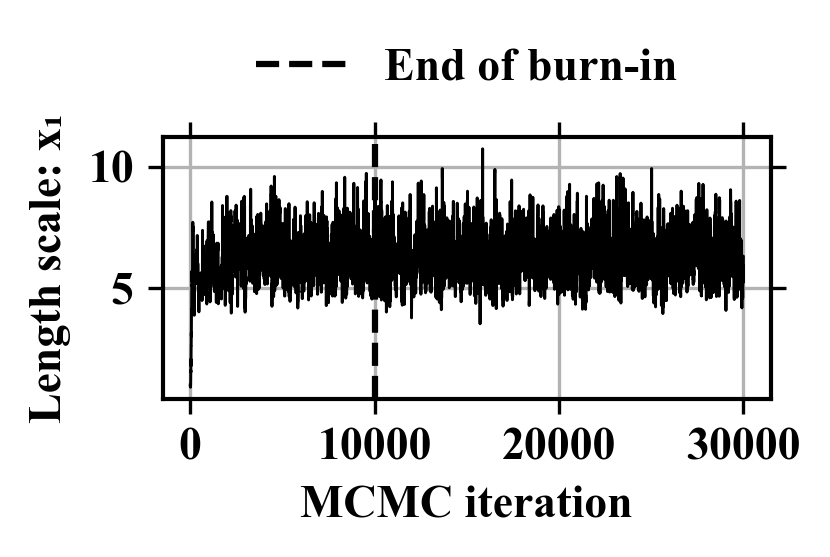

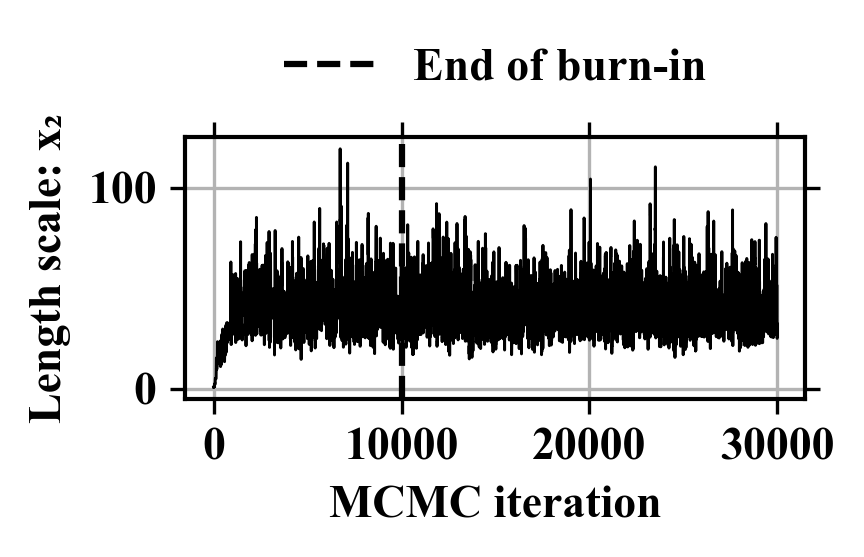

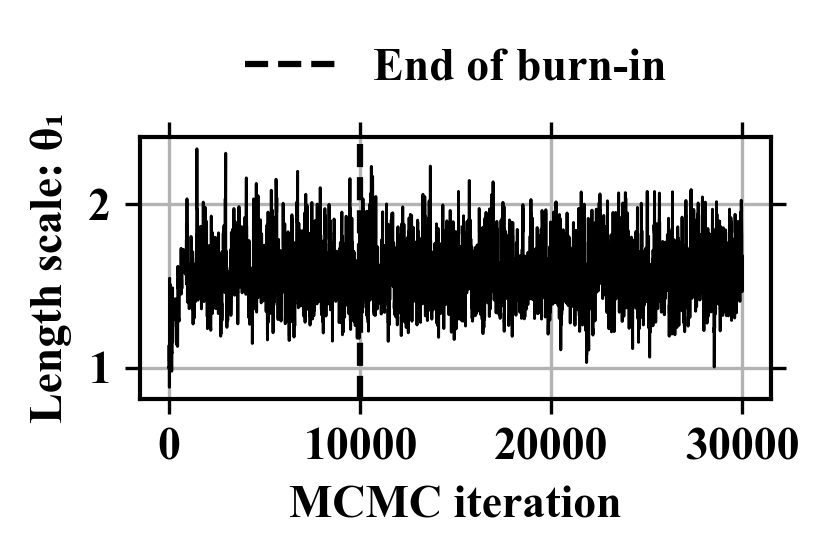

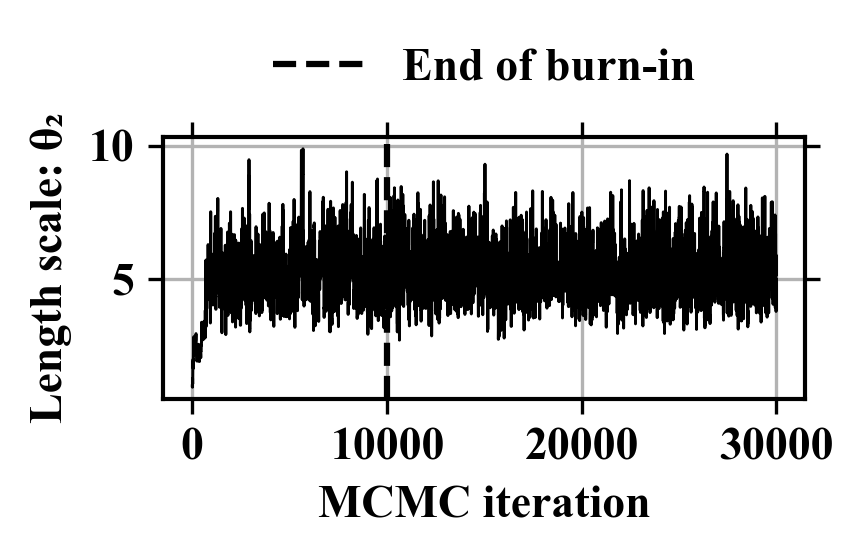

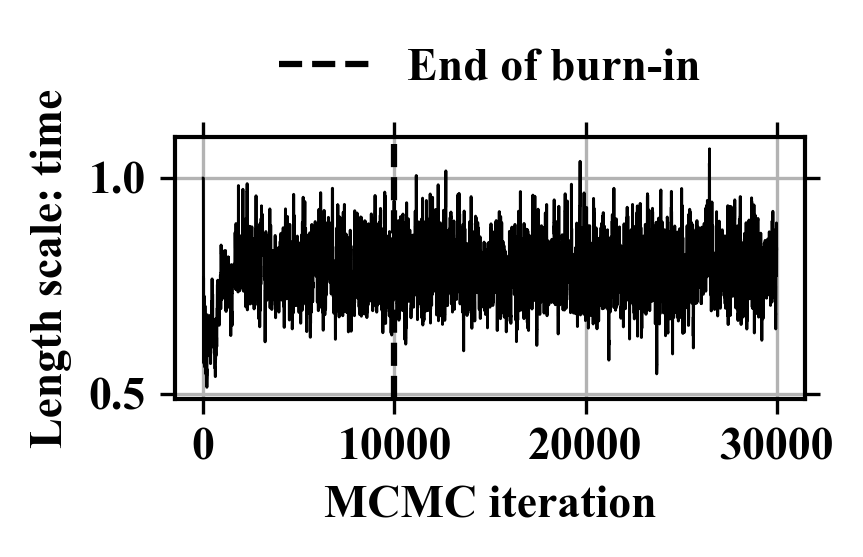

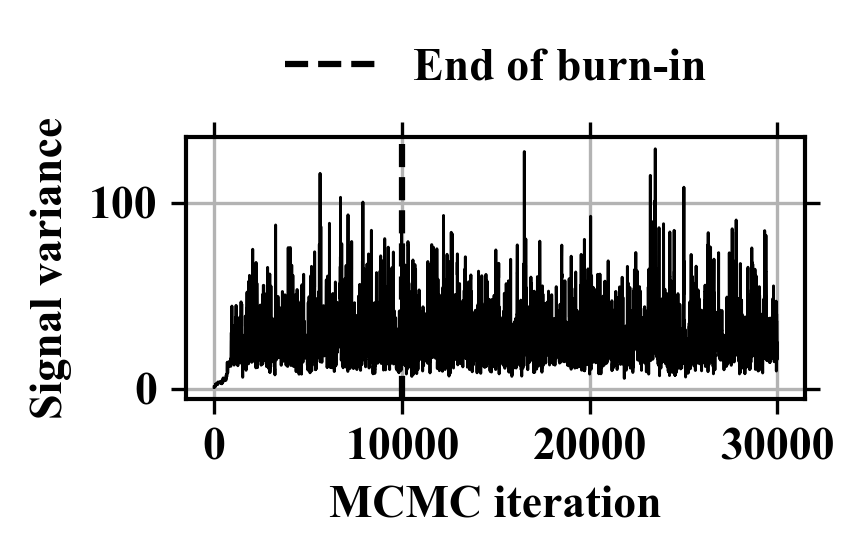

In [74]:
parameter_names = ['Length scale: x₁', 'Length scale: x₂', 'Length scale: θ₁', 'Length scale: θ₂', 'Length scale: time', 'Signal variance']
for j, label in enumerate(parameter_names):
    fig, ax = plt.subplots(figsize=(3, 2))
    ax.plot(samples[:, j], color='black', linewidth=0.7)
    ax.axvline(burn_in, color='black', linestyle='--', label='End of burn-in')
    ax.set(xlabel='MCMC iteration', ylabel=label)
    figure_legend(ax, ncol=1)
    fig.tight_layout()
    plt.show()

Plotting prior, truth and posterior curves FOR REGRESSION ONLY

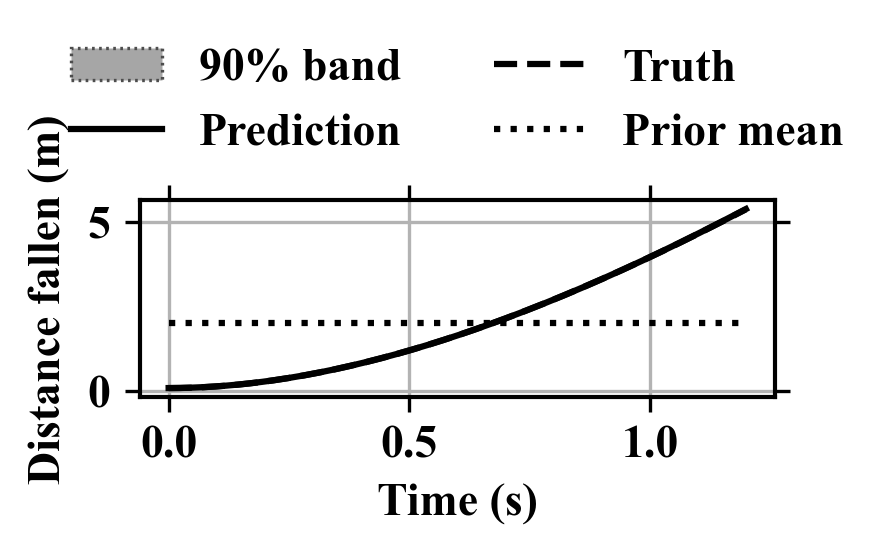

In [75]:
# Emulator regression curve at the first condition and true θ.
from scipy.linalg import solve_triangular
time_plot = np.linspace(0, 1.2, 150)
physical = np.column_stack((np.repeat(x_conditions[:1], len(time_plot), axis=0),
                            np.tile(theta_true, (len(time_plot), 1)), time_plot))
X_plot = qmc.scale(physical, lower_bounds, upper_bounds, reverse=True)
rng_predict = np.random.default_rng(123)
indices = rng_predict.choice(len(posterior_samples), min(200, len(posterior_samples)), replace=False)
predictive_draws = []
for index in indices:
    ls, variance = posterior_samples[index, :5], posterior_samples[index, 5]
    K = rbf_kernel(X_train, X_train, ls, variance) + alpha * np.eye(len(X_train))
    cross = rbf_kernel(X_train, X_plot, ls, variance)
    L = np.linalg.cholesky(K)
    v = solve_triangular(L, cross, lower=True)
    mu = v.T @ solve_triangular(L, y_train, lower=True)
    cov = rbf_kernel(X_plot, X_plot, ls, variance) - v.T @ v
    eigenvalues, eigenvectors = np.linalg.eigh((cov + cov.T) / 2)
    if eigenvalues.min() < -1e-8 * max(variance, 1.0):
        raise ValueError('Predictive covariance is not positive semidefinite')
    predictive_draws.append(y_mean + y_std * (mu + eigenvectors @ (
        np.sqrt(np.maximum(eigenvalues, 0)) * rng_predict.normal(size=len(time_plot)))))
predictive_draws = np.asarray(predictive_draws)
lower, upper = np.percentile(predictive_draws, [5, 95], axis=0)
fig, ax = plt.subplots(figsize=(3, 2))
ax.fill_between(time_plot, lower, upper, facecolor='0.65', edgecolor='0.3', linestyle=':', linewidth=0.8, label='90% band')
ax.plot(time_plot, predictive_draws.mean(axis=0), 'k-', label='Prediction')
ax.plot(time_plot, physics_model(x_conditions[0], theta_true, time_plot), 'k--', label='Truth')
ax.plot(time_plot, np.full_like(time_plot, y_mean), 'k:', label='Prior mean')
ax.set(xlabel='Time (s)', ylabel='Distance fallen (m)')
figure_legend(ax, ncol=2)
fig.tight_layout()
plt.show()

Freezing the trained GP emulator

In [76]:
# Freeze the trained emulator at posterior median hyperparameters
frozen_parameters = np.median(posterior_samples, axis=0)

frozen_lengthscale = frozen_parameters[:5]
frozen_signal_variance = frozen_parameters[5]

# Precompute the frozen training covariance
K_frozen = rbf_kernel(
    X_train,
    X_train,
    frozen_lengthscale,
    frozen_signal_variance
)

K_frozen += alpha * np.eye(len(X_train))
L_frozen = np.linalg.cholesky(K_frozen)

print("Frozen lengthscale:", frozen_lengthscale)
print("Frozen signal variance:", frozen_signal_variance)

Frozen lengthscale: [ 6.30927875 38.91508865  1.57137632  5.27501511  0.78471086]
Frozen signal variance: 24.558502431713194


Prediction function for the frozen emulator

In [77]:
def frozen_emulator_predict(x, theta, time):
    x, time, theta = np.asarray(x, float), np.asarray(time, float), np.asarray(theta, float)
    if x.shape != (len(time), 2) or theta.shape != (2,):
        raise ValueError('x must have shape (number of times, 2) and theta shape (2,)')
    X_new_physical = np.column_stack((x, np.broadcast_to(theta, (len(time), 2)), time))
    X_new = qmc.scale(X_new_physical, lower_bounds, upper_bounds, reverse=True)
    K_cross = rbf_kernel(X_train, X_new, frozen_lengthscale, frozen_signal_variance)
    K_new = rbf_kernel(X_new, X_new, frozen_lengthscale, frozen_signal_variance)
    v = np.linalg.solve(L_frozen, K_cross)
    weights = np.linalg.solve(L_frozen, y_train)
    return y_mean + y_std * (v.T @ weights), y_std**2 * (K_new - v.T @ v)

Discrepancy GP defined below. 

In [78]:
def discrepancy_kernel(time1, time2, discrepancy_lengthscale, discrepancy_signal_variance):
    time1, time2 = np.asarray(time1, float), np.asarray(time2, float)
    d = (time1[:, None] - time2[None, :]) / (upper_bounds[4] - lower_bounds[4])
    return discrepancy_signal_variance * np.exp(-0.5 * (d / discrepancy_lengthscale)**2)

Defining the calibration likelihood

In [79]:
def calibration_log_likelihood(
    theta,
    discrepancy_lengthscale,
    discrepancy_signal_variance
):
    # Frozen-emulator prediction at the observation locations
    emulator_mean, emulator_covariance = frozen_emulator_predict(
        x_obs, theta, t_obs
    )

    # Discrepancy covariance
    discrepancy_covariance = discrepancy_kernel(
        t_obs,
        t_obs,
        discrepancy_lengthscale,
        discrepancy_signal_variance
    )

    # Total uncertainty:
    # emulator + discrepancy + measurement noise
    total_covariance = (
        emulator_covariance
        + discrepancy_covariance
        + sigma_obs**2 * np.eye(len(x_obs))
        + 1e-8 * np.eye(len(x_obs))
    )

    residual = y_obs - emulator_mean

    try:
        L = np.linalg.cholesky(total_covariance)
    except np.linalg.LinAlgError:
        return -np.inf

    solved_residual = np.linalg.solve(L, residual)

    log_likelihood = (
        -0.5 * solved_residual @ solved_residual
        - np.sum(np.log(np.diag(L)))
        - 0.5 * len(y_obs) * np.log(2 * np.pi)
    )

    return log_likelihood

Defining priors for theta and discrepancy. 

In [80]:
from scipy.stats import lognorm

# Prior median for discrepancy variance in physical output units
discrepancy_variance_scale = (0.10 * y_std)**2

def calibration_log_prior(
    theta,
    discrepancy_lengthscale,
    discrepancy_signal_variance
):
    # Use the same theta bounds as the simulator design.
    theta_min, theta_max = lower_bounds[2:4], upper_bounds[2:4]
    # Uniform prior for theta within its physical bounds
    if np.any(theta < theta_min) or np.any(theta > theta_max):
        return -np.inf

    if discrepancy_lengthscale <= 0:
        return -np.inf

    if discrepancy_signal_variance <= 0:
        return -np.inf

    log_prior_theta = -np.sum(np.log(theta_max - theta_min))

    # Smooth discrepancy prior on normalized x
    log_prior_lengthscale = lognorm.logpdf(
        discrepancy_lengthscale,
        s=0.5,
        scale=0.5
    )

    # Prior favoring a relatively small discrepancy
    log_prior_variance = lognorm.logpdf(
        discrepancy_signal_variance,
        s=0.7,
        scale=discrepancy_variance_scale
    )

    return (
        log_prior_theta
        + log_prior_lengthscale
        + log_prior_variance
    )

Combining calibration prior and posterior into log posterior 

In [81]:
def calibration_log_posterior(
    theta,
    discrepancy_lengthscale,
    discrepancy_signal_variance
):
    log_prior_value = calibration_log_prior(
        theta,
        discrepancy_lengthscale,
        discrepancy_signal_variance
    )

    if not np.isfinite(log_prior_value):
        return -np.inf

    log_likelihood_value = calibration_log_likelihood(
        theta,
        discrepancy_lengthscale,
        discrepancy_signal_variance
    )

    return log_prior_value + log_likelihood_value


# Initial calibration values
initial_theta = np.array([1.0, 1.0])
initial_discrepancy_lengthscale = 0.5
initial_discrepancy_signal_variance = discrepancy_variance_scale

initial_log_posterior = calibration_log_posterior(
    initial_theta,
    initial_discrepancy_lengthscale,
    initial_discrepancy_signal_variance
)

print("Initial calibration log posterior:", initial_log_posterior)

Initial calibration log posterior: 22.949020147368753


Running MCMC for theta and 2 delta GP parameters

In [ ]:
rng_calibration = np.random.default_rng(2027)

def transformed_calibration_log_posterior(z):
    theta = z[:2]
    discrepancy_lengthscale = np.exp(z[2])
    discrepancy_signal_variance = np.exp(z[3])

    value = calibration_log_posterior(
        theta,
        discrepancy_lengthscale,
        discrepancy_signal_variance
    )

    if not np.isfinite(value):
        return -np.inf

    # Jacobian for the two log-transformed parameters
    return value + z[2] + z[3]


n_calibration_steps = 30000
calibration_burn_in = 10000  # Discard the initial iterations from posterior summaries

# Proposal SDs for:
# theta1, theta2, log discrepancy lengthscale, log discrepancy variance
proposal_sd = np.array([0.05, 0.05, 0.10, 0.10])

current_z = np.array([
    *initial_theta,
    np.log(initial_discrepancy_lengthscale),
    np.log(initial_discrepancy_signal_variance)
])

current_log_posterior = transformed_calibration_log_posterior(current_z)

calibration_samples = np.zeros((n_calibration_steps, 4))
accepted = 0

for i in range(n_calibration_steps):
    proposed_z = current_z + rng_calibration.normal(
        0.0,
        proposal_sd,
        size=4
    )

    proposed_log_posterior = (
        transformed_calibration_log_posterior(proposed_z)
    )

    log_acceptance_ratio = (
        proposed_log_posterior - current_log_posterior
    )

    if np.log(rng_calibration.uniform()) < log_acceptance_ratio:
        current_z = proposed_z
        current_log_posterior = proposed_log_posterior
        accepted += 1

    calibration_samples[i] = [
        current_z[0], current_z[1],
        np.exp(current_z[2]), np.exp(current_z[3])
    ]

calibration_posterior_samples = calibration_samples[calibration_burn_in:]

print("Burn-in iterations:", calibration_burn_in)
print("Posterior samples shape:", calibration_posterior_samples.shape)
print("Acceptance rate:", accepted / n_calibration_steps)
print("Sample columns: theta1, theta2, discrepancy lengthscale, discrepancy variance")

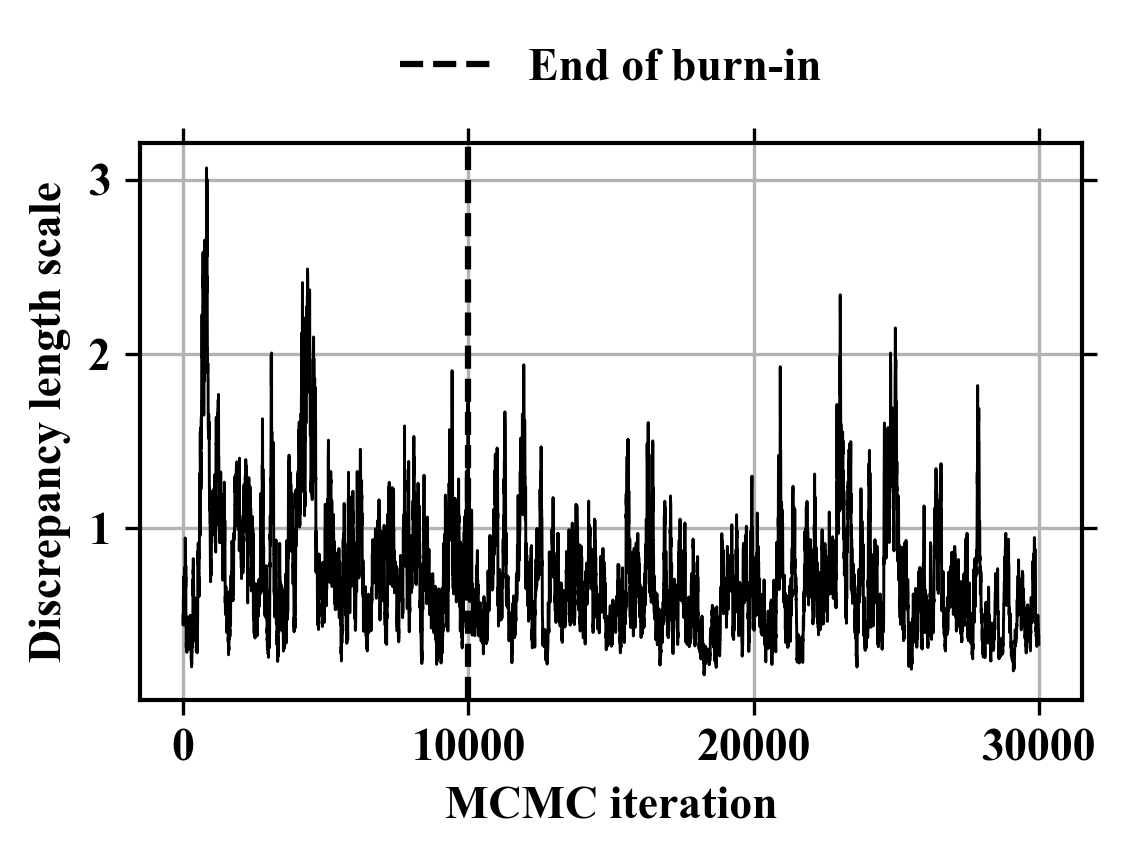

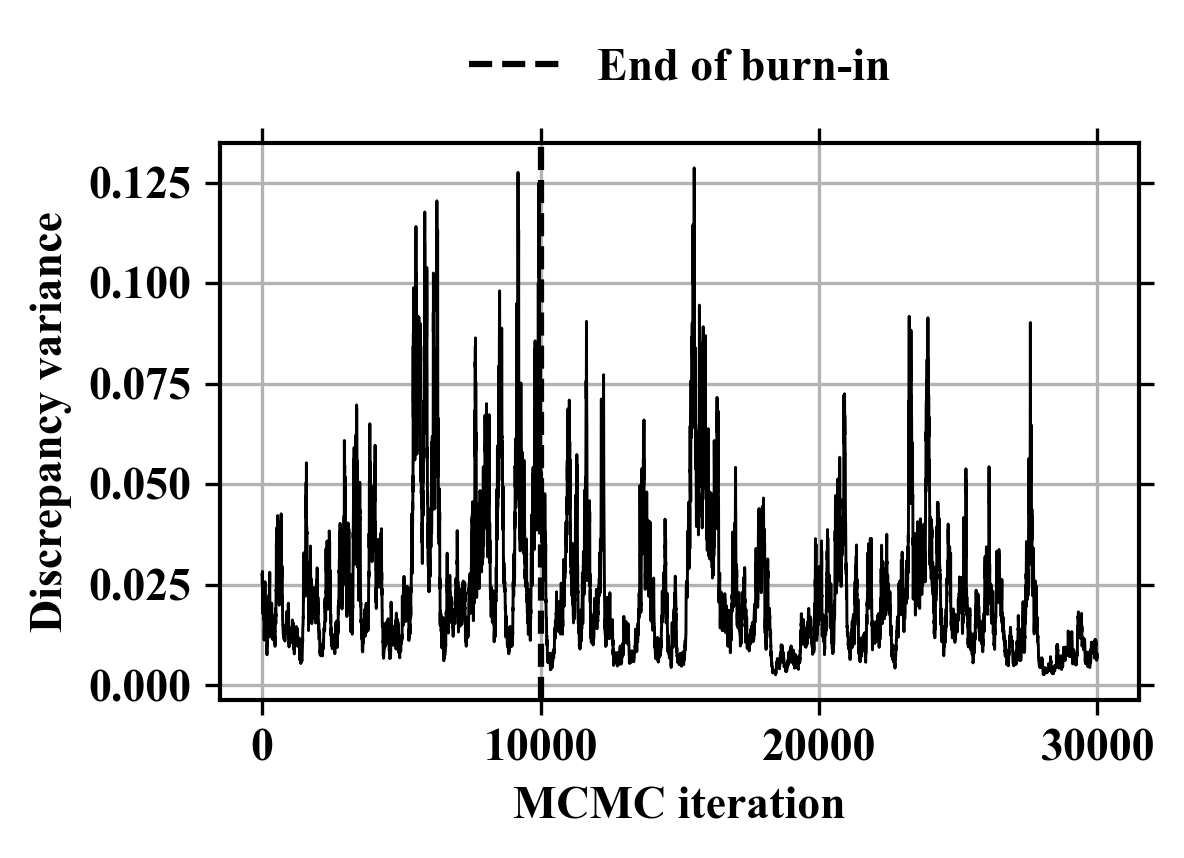

In [ ]:
# Trace plots for the discrepancy GP parameters
parameter_labels = ['Discrepancy length scale', 'Discrepancy variance']
iterations = np.arange(1, len(calibration_samples) + 1)

for column, label in zip([2, 3], parameter_labels):
    fig, ax = plt.subplots(figsize=(3, 2))
    ax.plot(iterations, calibration_samples[:, column], color='black', linewidth=0.7)
    ax.axvline(calibration_burn_in, color='black', linestyle='--', label='End of burn-in')
    ax.set_xlabel('MCMC iteration')
    ax.set_ylabel(label)
    figure_legend(ax)
    fig.tight_layout()
    plt.show()

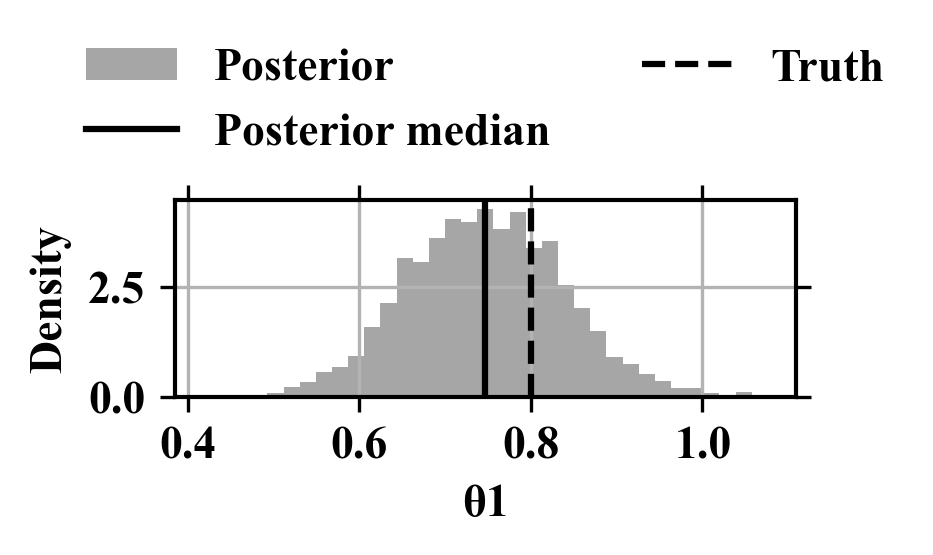

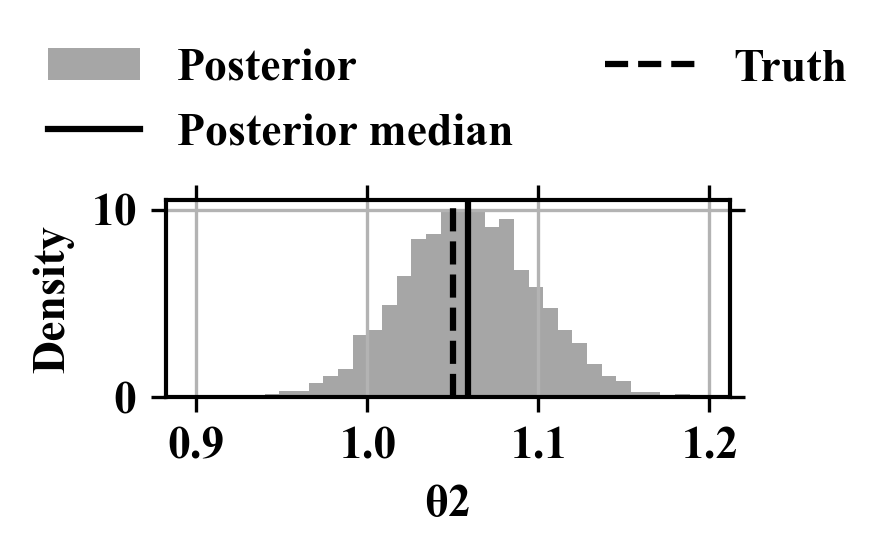

In [ ]:
for j in range(2):
    theta_posterior = calibration_posterior_samples[:, j]
    theta_median = np.median(theta_posterior)
    fig, ax = plt.subplots(figsize=(3, 2))
    ax.hist(theta_posterior, bins=35, density=True, color='0.65', label='Posterior')
    ax.axvline(theta_median, color='black', label='Posterior median')
    ax.axvline(theta_true[j], color='black', linestyle='--', label='Truth')
    ax.set(xlabel=f'θ{j+1}', ylabel='Density')
    figure_legend(ax, ncol=2)
    fig.tight_layout()
    plt.show()

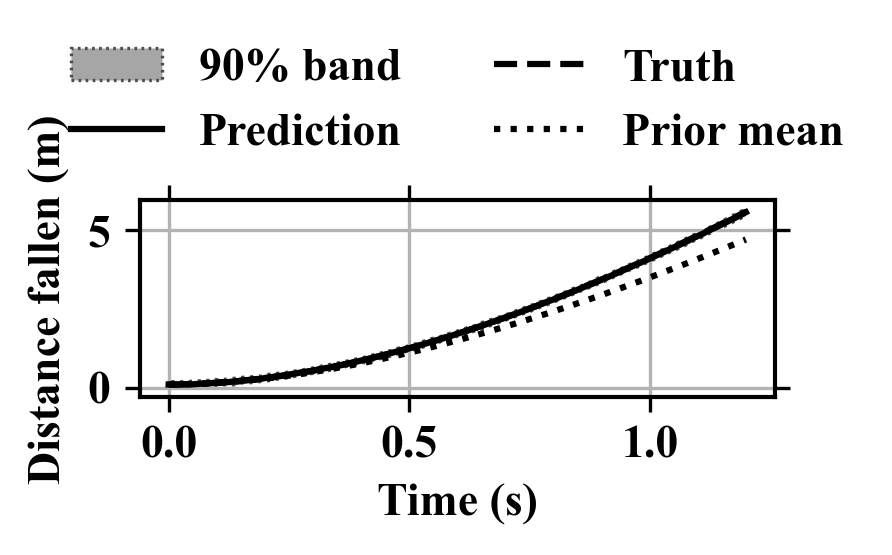

In [ ]:
# Predict future noisy observations for the first experimental condition.
from scipy.linalg import solve_triangular
time_plot = np.linspace(0, 1.2, 150)
x_plot = np.repeat(x_conditions[:1], len(time_plot), axis=0)
x_joint = np.vstack((x_obs, x_plot))
t_joint = np.concatenate((t_obs, time_plot))
n_obs = len(t_obs)
rng_predict = np.random.default_rng(2028)
indices = rng_predict.choice(len(calibration_posterior_samples), min(200, len(calibration_posterior_samples)), replace=False)
draws = []
for index in indices:
    theta = calibration_posterior_samples[index, :2]
    delta_length, delta_variance = calibration_posterior_samples[index, 2:]
    mean, cov = frozen_emulator_predict(x_joint, theta, t_joint)
    cov += discrepancy_kernel(t_joint, t_joint, delta_length, delta_variance)
    L = np.linalg.cholesky(cov[:n_obs, :n_obs] + (sigma_obs**2 + 1e-8) * np.eye(n_obs))
    v = solve_triangular(L, cov[:n_obs, n_obs:], lower=True)
    residual = solve_triangular(L, y_obs - mean[:n_obs], lower=True)
    mu = mean[n_obs:] + v.T @ residual
    C = cov[n_obs:, n_obs:] - v.T @ v
    # Independent measurement noise for future observations.
    C += sigma_obs**2 * np.eye(len(time_plot))
    eigenvalues, eigenvectors = np.linalg.eigh((C + C.T) / 2)
    if eigenvalues.min() < -1e-8 * max(1.0, np.max(np.abs(np.diag(cov)))):
        raise ValueError('Predictive covariance is not positive semidefinite')
    draws.append(mu + eigenvectors @ (np.sqrt(np.maximum(eigenvalues, 0)) * rng_predict.normal(size=len(time_plot))))
draws = np.asarray(draws)
lower, upper = np.percentile(draws, [5, 95], axis=0)
truth = physics_model(x_plot, theta_true, time_plot) + 0.15 * time_plot**2
prior_thetas = qmc.scale(qmc.LatinHypercube(d=2, seed=2028).random(50), lower_bounds[2:4], upper_bounds[2:4])
prior = np.mean([frozen_emulator_predict(x_plot, theta, time_plot)[0] for theta in prior_thetas], axis=0)
fig, ax = plt.subplots(figsize=(3, 2))
ax.fill_between(time_plot, lower, upper, facecolor='0.65', edgecolor='0.3', linestyle=':', linewidth=0.8, label='90% band')
ax.plot(time_plot, draws.mean(axis=0), 'k-', label='Prediction')
ax.plot(time_plot, truth, 'k--', label='Truth')
ax.plot(time_plot, prior, 'k:', label='Prior mean')
ax.set(xlabel='Time (s)', ylabel='Distance fallen (m)')
figure_legend(ax, ncol=2)
fig.tight_layout()
plt.show()